In [ ]:
# Locate the repo root (the directory holding config.py) so paths work from any cwd.
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
DATA = ROOT / "data" / "artifacts"

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)

In [3]:
# Bins over num_shared_chunks (how often a fact's subject and object appear in the
# same corpus chunk).  The 0 bin is kept in the per-relation view further down --
# 2,450 of 14,267 questions sit there and dropping them silently would misstate
# what the benchmark is made of -- but the bin-composition plots use the four
# non-zero bins as asked.
CHUNK_EDGES = [0, 1, 10, 100, 1_000, float("inf")]
CHUNK_LABELS = ["0", "1-10", "10-100", "100-1k", "1k+"]
NONZERO_BINS = ["1-10", "10-100", "100-1k", "1k+"]

# Drop questions whose fact never co-occurs in the corpus.  Restricts every figure
# to facts the corpus could actually have taught -- and changes what the shares in
# plot A are shares OF, so the axis label follows the flag.
DROP_ZERO_CHUNKS = True
# Questions held back from evaluation because they serve as the few-shot
# demonstrations, listed in data/artifacts/popqa/fewshot_withheld_15shot.csv (19 ids,
# derived as: all PopQA ids minus the ids present in a *_15shot_recallonly
# parquet; identical across every one of them).  The 15-shot result files already
# omit these, so this flag is a no-op on the recall side -- it matters for
# statistics computed from the FULL PopQA table, which otherwise describe a
# benchmark 19 questions larger than the one the models were scored on.
DROP_FEWSHOT_DEMOS = True
FEWSHOT_WITHHELD_CSV = DATA / "popqa/fewshot_withheld_15shot.csv"

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e5e4e0"
ACCENT = "#2a78d6"

# Sequential ramp for the ORDERED chunk bins and for the heatmaps.  Ordered data
# takes one hue light->dark, never a categorical set: 16 relations would blow past
# the ~8 usable categorical slots anyway.  Verified lightness-monotonic; only the
# two darkest steps take white text, which the cell/segment labels respect.
CMAP = LinearSegmentedColormap.from_list("chunks", ["#f4f8fd", "#164a86"])


def ramp(n: int) -> list:
    """n evenly spaced steps of the sequential ramp, light -> dark.

    Generated rather than hardcoded so the bin count can change with
    DROP_ZERO_CHUNKS without the darkest step stopping being 1k+.  Starts at 0.18
    so the lightest step still reads against the surface.
    """
    return [CMAP(x) for x in np.linspace(0.18, 1.0, n)]


# Only the darkest steps take white text; anything lighter needs dark ink.
def on_ramp_ink(idx: int, n: int) -> str:
    return SURFACE if idx >= n - 2 else INK

In [4]:
from datasets import load_dataset

ds = load_dataset("dhgottesman/popqa-kas")
qa = ds["train"].to_pandas()[["id", "prop", "num_shared_chunks"]]
_wh = pd.read_csv(FEWSHOT_WITHHELD_CSV)
WITHHELD_IDS = frozenset(_wh["id"]) if DROP_FEWSHOT_DEMOS else frozenset()
print(f"few-shot withheld: {len(_wh)} ids in {FEWSHOT_WITHHELD_CSV.name}"
      f"  (applied: {DROP_FEWSHOT_DEMOS})")

_n_all = len(qa)
if DROP_FEWSHOT_DEMOS:
    qa = qa[~qa["id"].isin(WITHHELD_IDS)].copy()
if DROP_ZERO_CHUNKS:
    qa = qa[qa["num_shared_chunks"] > 0].copy()
ACTIVE_CHUNK_LABELS = [b for b in CHUNK_LABELS if not (DROP_ZERO_CHUNKS and b == "0")]

qa["bin"] = pd.cut(qa["num_shared_chunks"], bins=CHUNK_EDGES,
                   labels=CHUNK_LABELS, right=False)

# Relations ordered by their share of the whole benchmark -- reused as the row
# order everywhere below so the three figures are read against one another.
PROP_ORDER = qa["prop"].value_counts().index.tolist()

share = qa["prop"].value_counts().to_frame("n")
share["share_pct"] = 100 * share["n"] / len(qa)
share["cumulative_pct"] = share["share_pct"].cumsum()
print(f"DROP_FEWSHOT_DEMOS={DROP_FEWSHOT_DEMOS} DROP_ZERO_CHUNKS={DROP_ZERO_CHUNKS}"
      f"  ->  {len(qa):,} of {_n_all:,} questions"
      f" | {qa['prop'].nunique()} relations")
share.round(2)

few-shot withheld: 19 ids in fewshot_withheld_15shot.csv  (applied: True)
DROP_FEWSHOT_DEMOS=True DROP_ZERO_CHUNKS=True  ->  11,799 of 14,267 questions | 16 relations


Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


In [5]:
# --- variety per bin -------------------------------------------------------
# "How many relations does this bin actually contain?" has two answers.  The
# count of distinct relations is a poor measure: a bin holding 15 relations where
# one covers 60% of it is not diverse.  Effective relations = exp(Shannon
# entropy) -- the number of equally-common relations that would give the same
# concentration -- so it drops when one relation dominates.
def variety(sub: pd.DataFrame) -> pd.Series:
    p = sub["prop"].value_counts(normalize=True)
    p = p[p > 0]
    if p.empty:                       # a bin can be empty once a filter removes it
        return pd.Series({"n": 0, "distinct_props": 0, "effective_props": np.nan,
                          "top_prop": None, "top_prop_pct": np.nan})
    return pd.Series({
        "n": len(sub),
        "distinct_props": sub["prop"].nunique(),
        "effective_props": float(np.exp(-(p * np.log(p)).sum())),
        "top_prop": p.index[0],
        "top_prop_pct": 100 * p.iloc[0],
    })


by_bin_variety = pd.DataFrame(
    {b: variety(qa[qa["bin"] == b]) for b in ACTIVE_CHUNK_LABELS}).T
by_bin_variety.round(2)

Loading ITables v2.8.1 from the init_notebook_mode cell... (need help?)


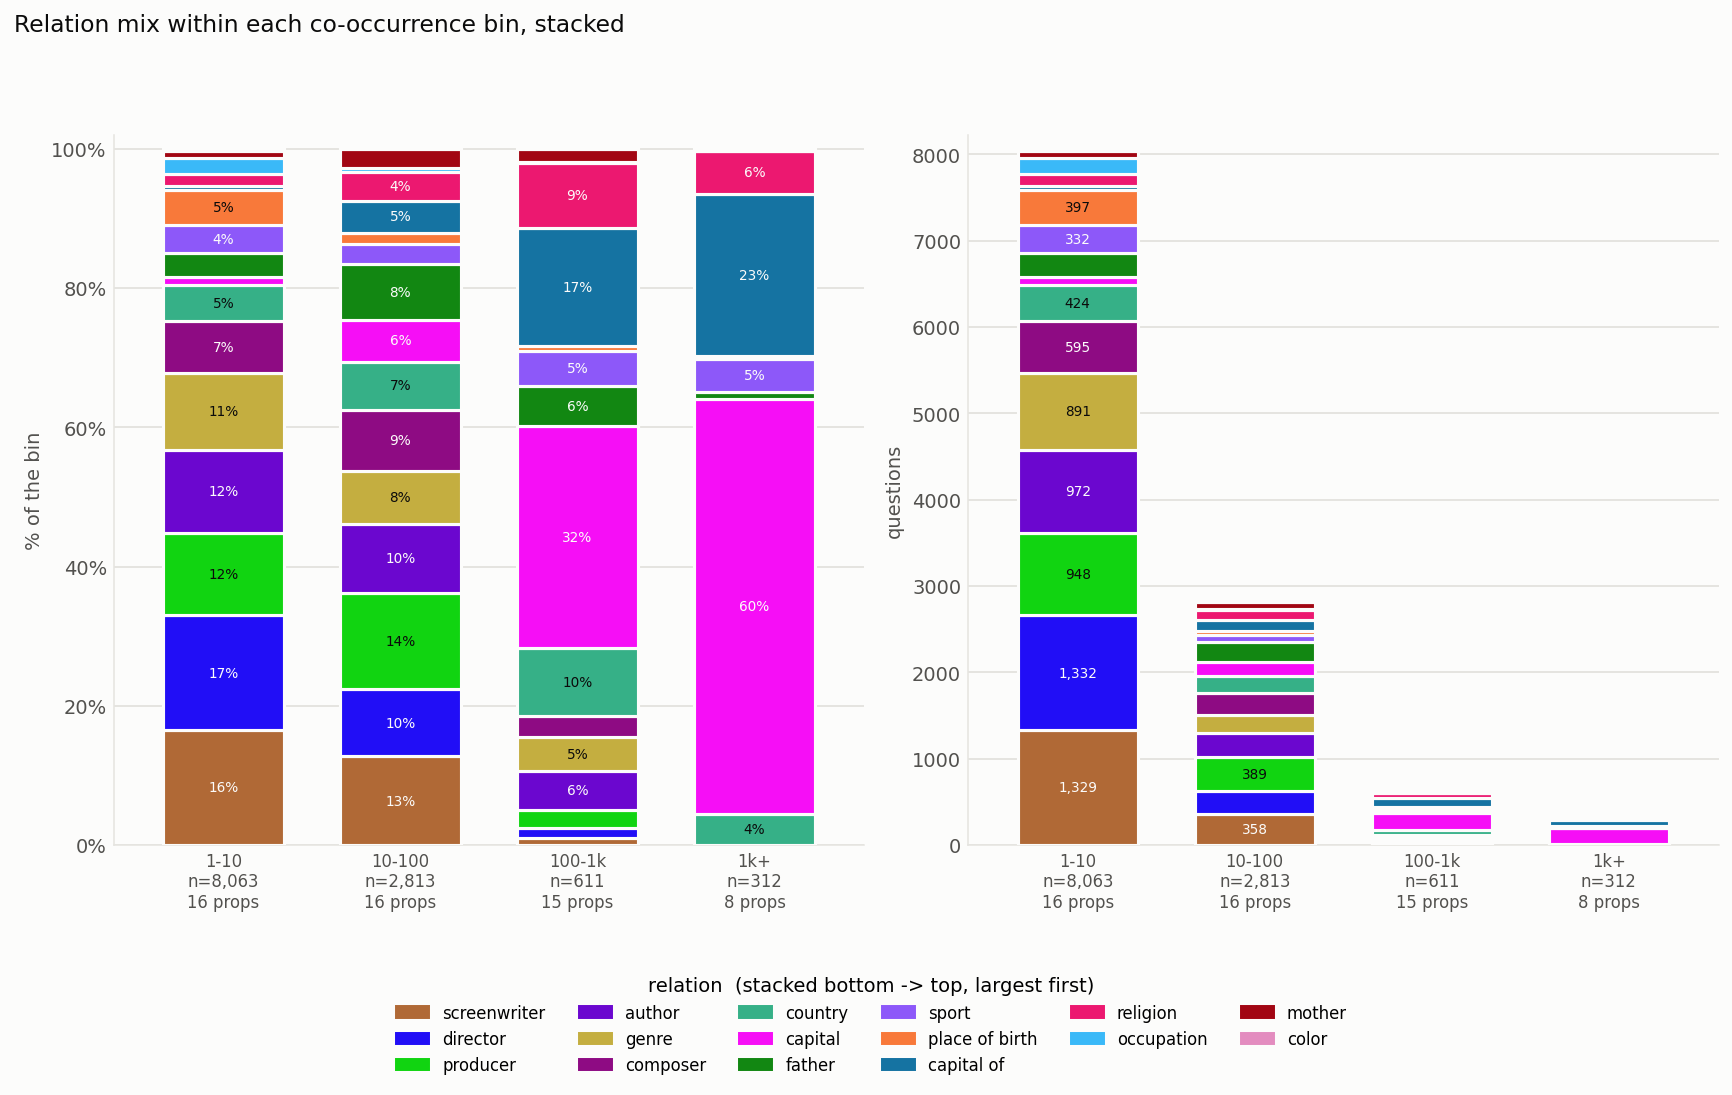

In [8]:

# --- PLOTS B2 & C2: the same data as stacked bars, one hue per relation -------
# 16 categorical hues is double the usual usable budget, so the palette was
# searched rather than picked: sampled HLS space, kept only colours inside the
# lightness band AND above the chroma floor, then ordered greedily so that
# NEIGHBOURS IN THE STACK are the most separated pairs (the only pairs that
# actually touch).  Result validates on all four colour checks -- worst adjacent
# dE 8.4 under protanopia, 31.9 under normal vision.  The one standing WARN is
# contrast vs surface on 6 of the 16, whose required relief is visible labels or a
# table view; both are present (segment labels plus the crosstabs above).
#
# Segments are stacked in PROP_ORDER and the palette is applied in that same
# order, so a relation keeps its hue across both panels and adjacent segments
# always draw from the far-apart end of the palette.
PALETTE16 = ["#b06936", "#210ef6", "#11d411", "#6b07cf", "#c4ae40", "#8e0b83",
             "#36b087", "#f60ef6", "#128712", "#8d58f9", "#f8793a", "#1573a2",
             "#ec1870", "#3ab9f8", "#a20613", "#e38cbf"]
PROP_COLOR = dict(zip(PROP_ORDER, PALETTE16))

ct = pd.crosstab(qa["prop"], qa["bin"])[NONZERO_BINS].loc[PROP_ORDER]
ct_pct = 100 * ct / ct.sum(axis=0)


def _ink_on(hex_color: str) -> str:
    """White on dark fills, dark ink on light ones."""
    r, g, b = (int(hex_color[k:k + 2], 16) / 255 for k in (1, 3, 5))
    f = lambda c: c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4
    lum = 0.2126 * f(r) + 0.7152 * f(g) + 0.0722 * f(b)
    return SURFACE if (1.05 / (lum + 0.05)) >= 3.0 else INK


fig5, axes5 = plt.subplots(1, 2, figsize=(12.4, 7.0), dpi=140)
fig5.patch.set_facecolor(SURFACE)
x = np.arange(len(NONZERO_BINS))

for ax, mat, ylab, fmt, min_frac in [
    (axes5[0], ct_pct, "% of the bin", lambda v: f"{v:.0f}%", 0.040),
    (axes5[1], ct, "questions", lambda v: f"{int(v):,}", 0.040),
]:
    ax.set_facecolor(SURFACE)
    axis_max = float(mat.sum(axis=0).max())
    bottom = np.zeros(len(NONZERO_BINS))
    for p in PROP_ORDER:
        h = mat.loc[p, NONZERO_BINS].values.astype(float)
        ax.bar(x, h, bottom=bottom, width=0.68, color=PROP_COLOR[p],
               edgecolor=SURFACE, linewidth=1.6, label=p, zorder=3)
        # Gate the label on VISUAL size, not on the column's own total: all four
        # bars share one y-axis, so a 25-question slice of the 615-tall bar passes
        # a per-column test yet is only a few pixels high.  Measure against the
        # tallest column instead.  Consequence: the two small bins carry no labels
        # in the counts panel -- read those off the % panel or the crosstab.
        for xi, (hi, bi) in enumerate(zip(h, bottom)):
            if hi / axis_max >= min_frac:
                ax.text(xi, bi + hi / 2, fmt(hi), ha="center", va="center",
                        fontsize=7, color=_ink_on(PROP_COLOR[p]), zorder=5)
        bottom += h

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{b}\nn={int(ct[b].sum()):,}\n{by_bin_variety.loc[b, 'distinct_props']:} props"
         for b in NONZERO_BINS], fontsize=8.5)
    ax.set_xlim(-0.62, len(NONZERO_BINS) - 0.38)
    ax.set_ylim(0, bottom.max() * 1.02)
    ax.set_ylabel(ylab, fontsize=10, color=INK_MUTED)
    if mat is ct_pct:
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_MUTED, length=0)

handles = [plt.Rectangle((0, 0), 1, 1, color=PROP_COLOR[p]) for p in PROP_ORDER]
fig5.legend(handles, PROP_ORDER, title="relation  (stacked bottom -> top, largest first)",
            frameon=False, ncols=6, fontsize=8.5, loc="lower center",
            bbox_to_anchor=(0.5, -0.10))
fig5.suptitle("Relation mix within each co-occurrence bin, stacked",
              fontsize=12, color=INK, x=0.006, ha="left", y=0.998)
# fig5.text(0.006, 0.955,
#           f"left: normalised within the bin.  right: raw counts.  "
#           f"capital is {ct_pct.loc['capital', '1k+']:.0f}% of the 1k+ bin, "
#           f"and {int(by_bin_variety.loc['1k+', 'distinct_props'])}/16 relations appear there at all", # type: ignore
#           fontsize=9, color=INK_MUTED, ha="left")
fig5.tight_layout(rect=(0, 0.06, 1, 0.94))
plt.show()


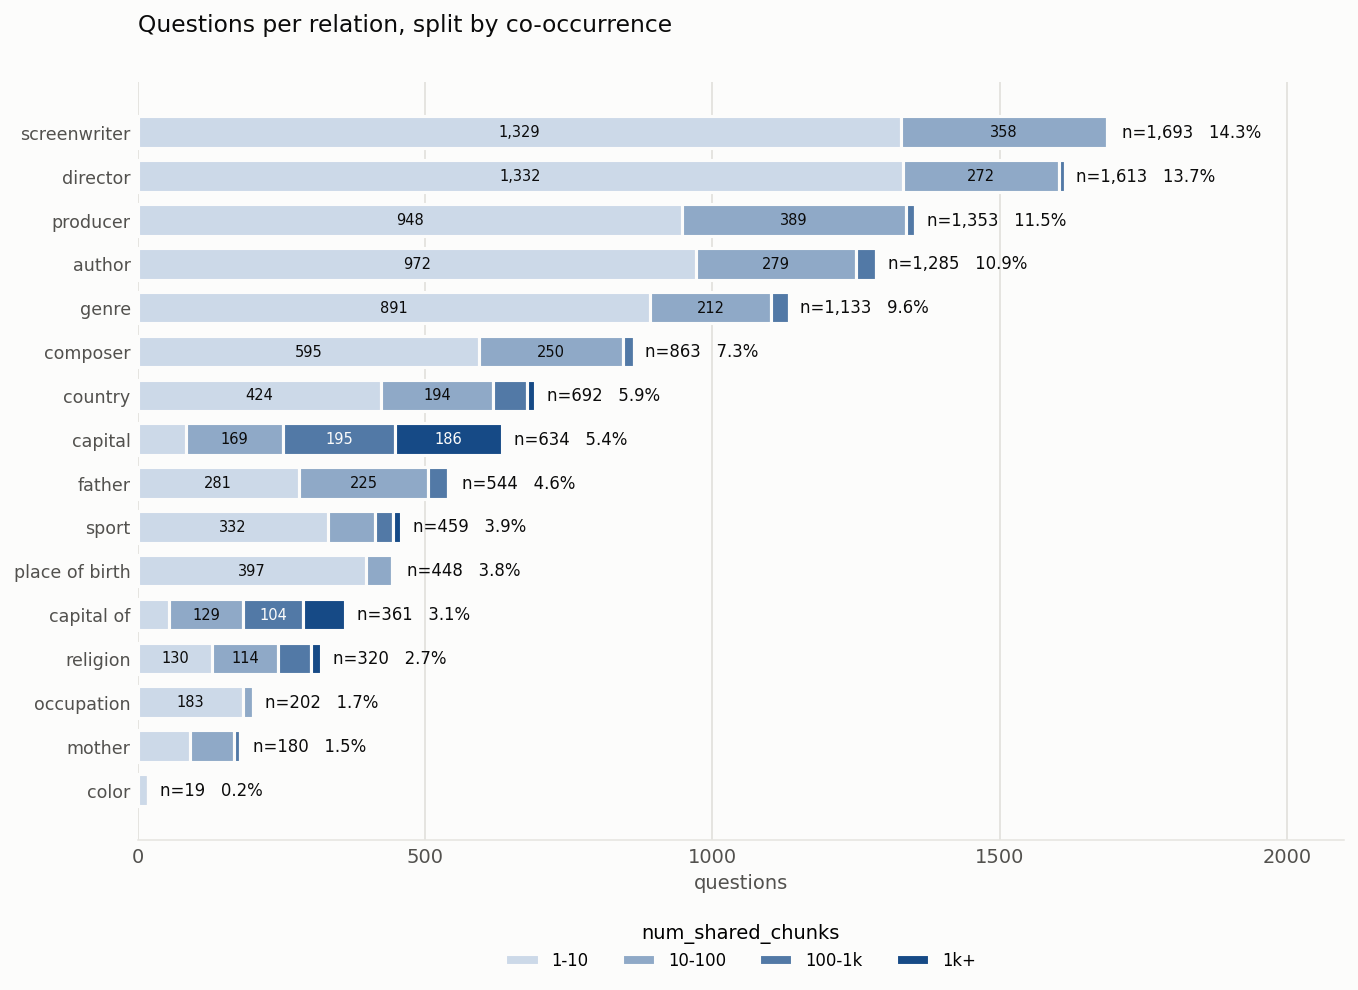

In [7]:

# --- PLOT E: plot D again, in absolute question counts ----------------------
# Plot D normalises each row to 100%, which shows a relation's SHAPE but throws
# away its size -- color (n=34) and screenwriter (n=1,999) get identical bar
# lengths there.  Here the widths are raw counts, so length carries the relation's
# size and the segments still carry its co-occurrence split.  Each segment is
# labelled with its question count where it is wide enough, and every bar carries
# its row total at the end.
cnt = pd.crosstab(qa["prop"], qa["bin"])[ACTIVE_CHUNK_LABELS]
cnt = cnt.loc[cnt.sum(axis=1).sort_values(ascending=False).index]
totals = cnt.sum(axis=1)

fig4, ax = plt.subplots(figsize=(9.8, 7.2), dpi=140)
fig4.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

y = np.arange(len(cnt))
left = np.zeros(len(cnt))
colors = ramp(len(ACTIVE_CHUNK_LABELS))
xmax = totals.max() * 1.24

for si, (colr, b) in enumerate(zip(colors, ACTIVE_CHUNK_LABELS)):
    w = cnt[b].values
    ax.barh(y, w, left=left, height=0.72, color=colr, label=b,
            edgecolor=SURFACE, linewidth=1.6, zorder=3)   # 2px gap between segments
    for yi, (wi, li) in enumerate(zip(w, left)):
        if wi >= 0.045 * xmax:          # only label segments wide enough to hold it
            ax.text(li + wi / 2, yi, f"{int(wi):,}", ha="center", va="center",
                    fontsize=7.5, color=on_ramp_ink(si, len(colors)), zorder=5)
    left += w

# Row total, plus that relation's share of the questions in scope.  The
# denominator is the filtered total (the same rows the bars are built from), so
# these sum to 100% and agree with plot A rather than silently using raw PopQA.
grand = int(totals.sum())
for yi, t in enumerate(totals):
    ax.annotate(f"n={int(t):,}   {100 * t / grand:.1f}%", xy=(t, yi), xytext=(6, 0),
                textcoords="offset points", va="center", ha="left",
                fontsize=8.5, color=INK)

ax.set_yticks(y); ax.set_yticklabels(cnt.index, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, xmax)
ax.xaxis.set_major_locator(plt.MaxNLocator(7, steps=[1, 2, 5, 10], integer=True))
ax.set_xlabel("questions", fontsize=10, color=INK_MUTED)
ax.set_title("Questions per relation, split by co-occurrence",
             fontsize=12, color=INK, loc="left", pad=26)
# ax.text(0, 1.012,
#         f"same data as above, unnormalised -- bar length is the relation's size.  "
#         f"labels: questions, then share of the {grand:,} in scope",
#         transform=ax.transAxes, fontsize=9, color=INK_MUTED, va="bottom")
ax.legend(title="num_shared_chunks", frameon=False,
          ncols=len(ACTIVE_CHUNK_LABELS), fontsize=8.5,
          loc="lower center", bbox_to_anchor=(0.5, -0.19))
ax.grid(axis="x", color=GRID, linewidth=1); ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK_MUTED, length=0)
fig4.tight_layout()
plt.show()
